# 23장 · 광자 — 예제 풀이

**열및통계물리2 · 교재 23장 광자 (Blundell & Blundell, *Concepts in Thermal Physics* 2판)**

교재 예제 23.1–23.4와 추가 문제(연습문제 23.3, 23.7)를 Python으로 확인한다. 위에서부터 순서대로 실행하면 된다.
방출 일률은 강의자료 기호 $j^\star$(교재 $F$)로 쓴다. 단위는 SI, 그래프 라벨은 영어로 쓴다.

In [1]:
# ── 0. 준비: 라이브러리와 물리 상수 ──────────────────────────────
import numpy as np
import scipy.constants as sc
from scipy import integrate, optimize, special
import matplotlib.pyplot as plt

# 물리 상수 (SI 단위). 출처: scipy.constants = CODATA 2018 권장값
kB   = sc.k            # 볼츠만 상수 [J/K]
h    = sc.h            # 플랑크 상수 [J s]
hbar = sc.hbar         # [J s]
c    = sc.c            # 광속 [m/s]
e    = sc.e            # 기본 전하 [C]  (1 eV = e J)
NA   = sc.N_A          # 아보가드로 수 [1/mol]
R    = sc.R            # 기체 상수 [J/(mol K)]
me   = sc.m_e          # 전자 질량 [kg]
mp   = sc.m_p          # 양성자 질량 [kg]
amu  = sc.atomic_mass  # 원자 질량 단위 u [kg]
muB  = sc.physical_constants['Bohr magneton'][0]   # 보어 자기량 [J/T]
mu0  = sc.mu_0         # 진공 투자율 [N/A^2]
sigma_SB = sc.Stefan_Boltzmann                      # 스테판-볼츠만 상수 [W m^-2 K^-4]

plt.rcParams.update({'figure.figsize': (6.4, 4.0), 'axes.grid': True, 'grid.alpha': 0.3})

def compare(label, value, book, unit='', rtol=0.05):
    """계산값과 교재 답을 나란히 출력한다. rtol: 허용 상대오차 (교재 답은 보통 유효숫자 2자리)."""
    rel = abs(value - book) / abs(book)
    flag = 'OK' if rel <= rtol else 'CHECK'
    print(f'{label}: computed = {value:.4g} {unit} | textbook = {book:.4g} {unit} | rel. diff = {rel:.2%} [{flag}]')
    return rel

print('Setup complete. numpy', np.__version__)

Setup complete. numpy 2.5.3


## 공통 도구 — 플랑크 분포

$u_\lambda=\dfrac{8\pi hc}{\lambda^5}\dfrac{1}{e^{hc/\lambda k_BT}-1}$ (교재 식 23.44), $u=\int u_\lambda d\lambda=\dfrac{4\sigma}{c}T^4$ (23.49), $j^\star=\tfrac14cu=\sigma T^4$ (23.22).

In [2]:
def u_lambda(lam, T):
    """스펙트럼 에너지 밀도 [J m^-3 m^-1] (교재 식 23.44)"""
    return 8 * np.pi * h * c / lam**5 / np.expm1(h * c / (lam * kB * T))

def band_fraction(l1, l2, T):
    """파장 l1–l2 사이에 있는 흑체 복사 에너지의 비율 (무차원 x = hc/(lambda k T) 로 적분)"""
    f = lambda x: x**3 / np.expm1(x)
    x1, x2 = h * c / (l2 * kB * T), h * c / (l1 * kB * T)
    return integrate.quad(f, x1, x2, epsabs=0, epsrel=1e-10)[0] / (np.pi**4 / 15)

# 확인: 전체 적분 = 4 sigma T^4 / c
T = 300.0
total = integrate.quad(lambda l: u_lambda(l, T), 1e-7, 1e-2, limit=500, epsabs=0, epsrel=1e-10, points=[1e-5, 1e-4])[0]
print(f'integral of u_lambda at 300 K = {total:.6e} J/m^3,  4 sigma T^4 / c = {4 * sigma_SB * T**4 / c:.6e} J/m^3')

integral of u_lambda at 300 K = 6.128244e-06 J/m^3,  4 sigma T^4 / c = 6.128244e-06 J/m^3


## 예제 23.1 — 흰 머그잔과 검은 머그잔 (교재 346쪽)

**문제 요약.** 모양·재질이 같고 가시광에서의 색만 다른 두 머그잔 중 어느 쪽이 커피를 더 따뜻하게 유지하는가? 교재의 답: 가시광의 색은 중요하지 않다. 뜨거운 잔은 대부분 적외선을 내므로 적외선에서의 흡수율(=방사율, 키르히호프 법칙)이 결정한다.

**풀이 아이디어.** 키르히호프 법칙의 근거를 수치로 보인다. **가정:** 머그잔 표면 온도 350 K. 이 온도의 흑체 복사 중 가시광(400–700 nm)과 적외선(> 2.5 μm)이 차지하는 비율을 계산한다.

T = 350.0 K: peak wavelength = 8.3 um
fraction of emitted power in visible 400-700 nm = 1.03e-21
fraction at wavelengths > 2.5 um (infrared)    = 0.999940


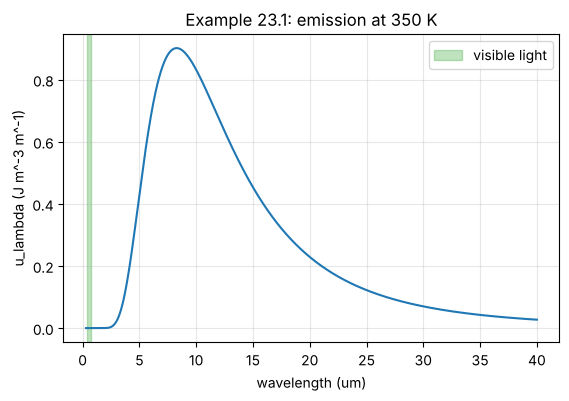

In [3]:
T = 350.0
vis = band_fraction(400e-9, 700e-9, T)
ir = band_fraction(2.5e-6, 1.0, T)
lam_max = 2.897771955e-3 / T          # 빈 법칙 상수 [m K] (교재 식 23.55: 2.9 mm K)
print(f'T = {T} K: peak wavelength = {lam_max * 1e6:.1f} um')
print(f'fraction of emitted power in visible 400-700 nm = {vis:.2e}')
print(f'fraction at wavelengths > 2.5 um (infrared)    = {ir:.6f}')
lams = np.linspace(0.3e-6, 40e-6, 1000)
plt.plot(lams * 1e6, u_lambda(lams, T))
plt.axvspan(0.4, 0.7, color='C2', alpha=0.3, label='visible light')
plt.xlabel('wavelength (um)'); plt.ylabel('u_lambda (J m^-3 m^-1)'); plt.legend(); plt.title('Example 23.1: emission at 350 K'); plt.show()

**해석.** 350 K 흑체 복사에서 가시광 비율은 $10^{-21}$ 수준이고, 사실상 전부 적외선(봉우리 약 8 μm)이다. 그래서 가시광에서 검게 보이는지 희게 보이는지는 복사 냉각에 아무 정보도 주지 않는다. 필요한 것은 적외선에서의 방사율이다(실제 냉각에는 대류·전도·증발도 기여한다).

## 예제 23.2 — 지구의 온도 추정 (교재 346–347쪽)

**문제 요약.** 태양과 지구를 흑체로 보고, 지구가 받는 일률과 내는 일률을 같게 놓아 $T_{\rm Earth}/T_{\rm Sun}=\sqrt{R_{\rm Sun}/2D}$ (23.18)을 보인다. $R_{\rm Sun}=7\times10^8$ m, $D=1.5\times10^{11}$ m, $T_{\rm Sun}=5800$ K. 교재 답: $T_{\rm Earth}=280$ K.

**풀이 아이디어.** 흡수 $L\,\pi R_E^2/4\pi D^2$ (23.20) = 방출 $4\pi R_E^2\sigma T_E^4$ (23.21), $L=4\pi R_S^2\sigma T_S^4$ (23.19). 해석식과 수치 근찾기를 모두 해 본다.

In [4]:
R_sun, D, T_sun = 7e8, 1.5e11, 5800.0          # 교재 값 [m], [m], [K]
R_E = 6.4e6                                    # 지구 반지름 [m] (결과에서 약분되므로 아무 값이나 가능)
L = 4 * np.pi * R_sun**2 * sigma_SB * T_sun**4                         # (23.19)
absorbed = L * np.pi * R_E**2 / (4 * np.pi * D**2)                     # (23.20)
T_E_root = optimize.brentq(lambda TE: absorbed - 4 * np.pi * R_E**2 * sigma_SB * TE**4, 10, 1000)
T_E_formula = T_sun * np.sqrt(R_sun / (2 * D))                         # (23.18)
print(f'L_sun = {L:.3e} W')
print(f'T_Earth (root) = {T_E_root:.2f} K,  T_Earth (formula 23.18) = {T_E_formula:.2f} K')
compare('T_Earth', T_E_formula, 280, 'K');

L_sun = 3.951e+26 W
T_Earth (root) = 280.17 K,  T_Earth (formula 23.18) = 280.17 K
T_Earth: computed = 280.2 K | textbook = 280 K | rel. diff = 0.06% [OK]


**해석.** 흑체 근사로 구한 지구 온도는 280 K로 교재 값과 같다. 받는 면적($\pi R_E^2$)과 내는 면적($4\pi R_E^2$)이 4배 다른 것이 핵심이고, 지구 반지름은 약분된다. 반사율(알베도)과 대기 효과는 넣지 않았다(연습문제 23.1).

## 예제 23.3 — 햇빛의 복사 압력 (교재 348쪽)

**문제 요약.** 단위 면적당 일률 $I=1370$ W m⁻²인 햇빛이 수직으로 들어올 때 복사 압력을 구하고 대기압과 비교한다. 교재 답: $p=I/c=4.6\ \mu$Pa (23.28), 대기압($10^5$ Pa)보다 약 10자리 작다.

**풀이 아이디어.** 한 방향 광선은 $p=I/c$ (완전 흡수, 23.27). 완전 반사면은 운동량 변화가 두 배라 $2I/c$이다.

In [5]:
I = 1370.0                                  # [W/m^2] (교재 입력값)
p_abs, p_ref = I / c, 2 * I / c
compare('radiation pressure (absorbing)', p_abs * 1e6, 4.6, 'uPa')
print(f'perfect reflector: {p_ref * 1e6:.2f} uPa;  ratio to 1e5 Pa = {p_abs / 1e5:.1e}  (log10 = {np.log10(p_abs / 1e5):.1f})')

radiation pressure (absorbing): computed = 4.57 uPa | textbook = 4.6 uPa | rel. diff = 0.66% [OK]
perfect reflector: 9.14 uPa;  ratio to 1e5 Pa = 4.6e-11  (log10 = -10.3)


**해석.** 완전 흡수면의 복사 압력은 4.6 μPa로 교재 값과 같고, 대기압의 $5\times10^{-11}$배이다. 한 방향 광선에는 등방 복사의 $p=u/3$을 쓰지 않는다(교재 23.4절).

## 예제 23.4 — 증폭과 밀도반전 (교재 358–359쪽)

**문제 요약.** 흡수율 $N_1B_{12}u_\omega$와 유도방출률 $N_2B_{21}u_\omega$를 비교해, 흡수보다 유도방출이 많으려면 $N_2/g_2>N_1/g_1$ (23.64, 밀도반전)이어야 함을 보인다.

**풀이 아이디어.** $g_1B_{12}=g_2B_{21}$ (23.62)를 쓰면 조건은 $N_2/g_2>N_1/g_1$이다. 열평형에서는 $\dfrac{N_2/g_2}{N_1/g_1}=e^{-\hbar\omega/k_BT}$ (23.60)이므로 양의 온도에서 항상 1보다 작다.
**가정:** 전이 파장 633 nm, $g_1=g_2=1$.

T =       300 K: (N2/g2)/(N1/g1) = 1.246e-33  -> stimulated/absorbed = 1.246e-33  (gain needs > 1)
T =      3000 K: (N2/g2)/(N1/g1) = 5.124e-04  -> stimulated/absorbed = 5.124e-04  (gain needs > 1)
T =     30000 K: (N2/g2)/(N1/g1) = 4.688e-01  -> stimulated/absorbed = 4.688e-01  (gain needs > 1)
T =   1000000 K: (N2/g2)/(N1/g1) = 9.775e-01  -> stimulated/absorbed = 9.775e-01  (gain needs > 1)


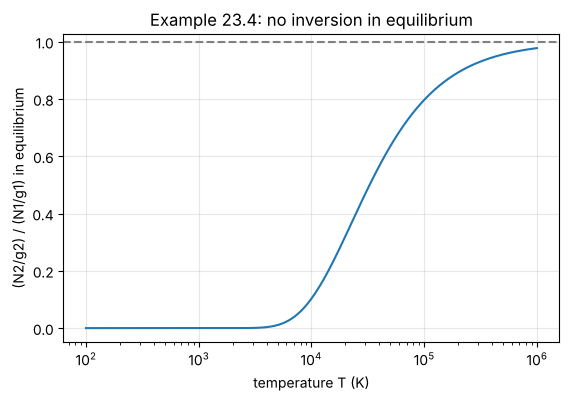

In [6]:
lam0 = 633e-9; hw = h * c / lam0
Ts = np.logspace(2, 6, 200)
ratio = np.exp(-hw / (kB * Ts))
for T in (300, 3000, 30000, 1e6):
    r = np.exp(-hw / (kB * T))
    print(f'T = {T:>9.0f} K: (N2/g2)/(N1/g1) = {r:.3e}  -> stimulated/absorbed = {r:.3e}  (gain needs > 1)')
plt.semilogx(Ts, ratio); plt.axhline(1, ls='--', c='gray')
plt.xlabel('temperature T (K)'); plt.ylabel('(N2/g2) / (N1/g1) in equilibrium'); plt.title('Example 23.4: no inversion in equilibrium'); plt.show()

**해석.** 열평형에서 들뜬 준위의 점유 비율은 $e^{-\hbar\omega/k_BT}<1$이고, 온도를 아무리 높여도 1에 다가갈 뿐 넘지 못한다. 따라서 두 준위만으로는 열평형에서 증폭이 일어나지 않으며, 레이저는 추가 준위와 비평형 펌핑으로 밀도반전을 만든다.

## 추가 문제 — 연습문제 23.3: 우주 배경 복사 (교재 360쪽)

**문제 요약.** $T=2.73$ K인 우주 배경 복사(CMB)에 대해 (a) 광자 에너지 밀도, (b) 펼친 손바닥에 매초 떨어지는 광자 수, (c) 손바닥에 매초 전달되는 에너지, (d) 복사 압력을 구한다. 교재에 수치 답은 없다.

**풀이 아이디어.** (a) $u=4\sigma T^4/c$. (b) 광자 수밀도 $n=\dfrac{2\zeta(3)}{\pi^2}\left(\dfrac{k_BT}{\hbar c}\right)^3$ (23.74), 한쪽 면에 닿는 선속 $\Phi=\tfrac14nc$ (23.5). (c) $j^\star=\sigma T^4$. (d) 등방 복사 $p=u/3$ (23.24). **가정:** 손바닥 넓이 $A=0.01$ m² (10 cm × 10 cm).

In [7]:
T, A = 2.73, 0.01
u = 4 * sigma_SB * T**4 / c
n_ph = 2 * special.zeta(3) / np.pi**2 * (kB * T / (hbar * c))**3
Phi = 0.25 * n_ph * c
print(f'(a) u = {u:.3e} J/m^3  ({u / e * 1e-6:.3f} eV/cm^3)')
print(f'    photon number density n = {n_ph:.3e} m^-3  ({n_ph * 1e-6:.0f} per cm^3)')
print(f'(b) photons per second on the palm = {Phi * A:.3e} s^-1')
print(f'(c) power on the palm = {sigma_SB * T**4 * A:.3e} W')
print(f'(d) radiation pressure p = u/3 = {u / 3:.3e} Pa')

(a) u = 4.202e-14 J/m^3  (0.262 eV/cm^3)
    photon number density n = 4.128e+08 m^-3  (413 per cm^3)
(b) photons per second on the palm = 3.094e+14 s^-1
(c) power on the palm = 3.150e-08 W
(d) radiation pressure p = u/3 = 1.401e-14 Pa


**해석.** CMB의 에너지 밀도는 약 $4\times10^{-14}$ J/m³(0.26 eV/cm³)이고, 광자 수밀도는 약 410개/cm³이다. 손바닥에는 매초 약 $3\times10^{14}$개의 광자가 떨어지지만 전달되는 일률은 $3\times10^{-8}$ W 정도로 매우 작다.

## 추가 문제 — 연습문제 23.7: 광자 기체의 광자 수와 광자당 에너지·엔트로피 (교재 361쪽)

**문제 요약.** $N=\dfrac{2\zeta(3)}{\pi^2}\left(\dfrac{k_BT}{\hbar c}\right)^3V$ (23.74), $U/N=\dfrac{\pi^4}{30\zeta(3)}k_BT=2.701k_BT$ (23.75), $S/N=\dfrac{2\pi^4}{45\zeta(3)}k_B=3.602k_B$ (23.76)를 보이고 고전 이상기체($U=\tfrac32Nk_BT$)와 비교한다.

**풀이 아이디어.** $N\propto\int x^2/(e^x-1)dx$, $U\propto\int x^3/(e^x-1)dx$를 수치적분하고, $S=(U-F)/T$와 $F=-U/3$ (연습문제 23.6, $U=-3F$)으로 $S=\tfrac43U/T$를 쓴다.

In [8]:
I2 = integrate.quad(lambda x: x**2 / np.expm1(x), 0, 200, epsabs=0, epsrel=1e-12)[0]   # = 2 zeta(3)
I3 = integrate.quad(lambda x: x**3 / np.expm1(x), 0, 200, epsabs=0, epsrel=1e-12)[0]   # = pi^4/15
print(f'int x^2/(e^x-1) = {I2:.6f},  2 zeta(3) = {2 * special.zeta(3):.6f};   int x^3/(e^x-1) = {I3:.6f},  pi^4/15 = {np.pi**4 / 15:.6f}')
U_per_N = I3 / I2                       # U/N in k_B T  (g(omega) ∝ omega^2 의 공통 계수는 약분)
S_per_N = 4 / 3 * U_per_N               # S = (4/3) U / T
compare('U/N (k_B T)', U_per_N, 2.701, 'k_B T', rtol=1e-3)
compare('S/N (k_B)', S_per_N, 3.602, 'k_B', rtol=1e-3)
print('classical monatomic ideal gas: U/N = 1.5 k_B T')

int x^2/(e^x-1) = 2.404114,  2 zeta(3) = 2.404114;   int x^3/(e^x-1) = 6.493939,  pi^4/15 = 6.493939
U/N (k_B T): computed = 2.701 k_B T | textbook = 2.701 k_B T | rel. diff = 0.01% [OK]
S/N (k_B): computed = 3.602 k_B | textbook = 3.602 k_B | rel. diff = 0.01% [OK]
classical monatomic ideal gas: U/N = 1.5 k_B T


**해석.** 광자 하나의 평균 에너지는 $2.701k_BT$, 평균 엔트로피는 $3.602k_B$로 교재 값과 일치한다. 고전 단원자 기체의 $1.5k_BT$보다 크며, 광자 수 자체가 $T^3$에 비례해 온도와 함께 변한다는 점이 다르다($\mu_\gamma=0$).